## Kaggle API Setup

To download datasets directly from Kaggle, you'll need to install the `kaggle` package and set up your API credentials.

1.  **Install the Kaggle package**: Run `pip install kaggle` in a code cell.
2.  **Generate Kaggle API Token**: Go to your Kaggle account settings (`https://www.kaggle.com/me/account`) and click 'Create New API Token'. This will download a `kaggle.json` file.
3.  **Upload `kaggle.json`**: In Colab, click the folder icon on the left sidebar, then the upload icon. Upload your `kaggle.json` file to the session storage. Alternatively, you can move it to `~/.kaggle/` in your Colab environment using shell commands.

Once `kaggle.json` is in place, the following cells will download the dataset.

In [ ]:
# Install Kaggle API client
%pip install kaggle

# Make sure the kaggle.json file is uploaded to your Colab session's root directory
# If it's in a different location, adjust the path below.
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

# Download the dataset
!kaggle datasets download -d rakannimer/air-passengers

# Unzip the downloaded file
!unzip air-passengers.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/rakannimer/air-passengers
License(s): DbCL-1.0
100% 764/764 [00:00<00:00, 1.90MB/s]

Archive:  air-passengers.zip
  inflating: AirPassengers.csv       


## Load and Preprocess Data

In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('AirPassengers.csv')

# Display the first 5 rows of the dataframe
display(df.head())

# Display information about the dataframe, including data types and non-null counts
display(df.info())

,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Month        144 non-null    object
 1   #Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


None

In [ ]:
# Convert 'Month' to datetime and set as index
df['Month'] = pd.to_datetime(df['Month'])
df.set_index('Month', inplace=True)

# Rename '#Passengers' column for easier access
df.rename(columns={'#Passengers': 'Passengers'}, inplace=True)

# Display the first few rows with the new index and column name
display(df.head())

# Check for any missing values after preprocessing
display(df.isnull().sum())

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


,0
Passengers,0


## Visualize the Time Series Data

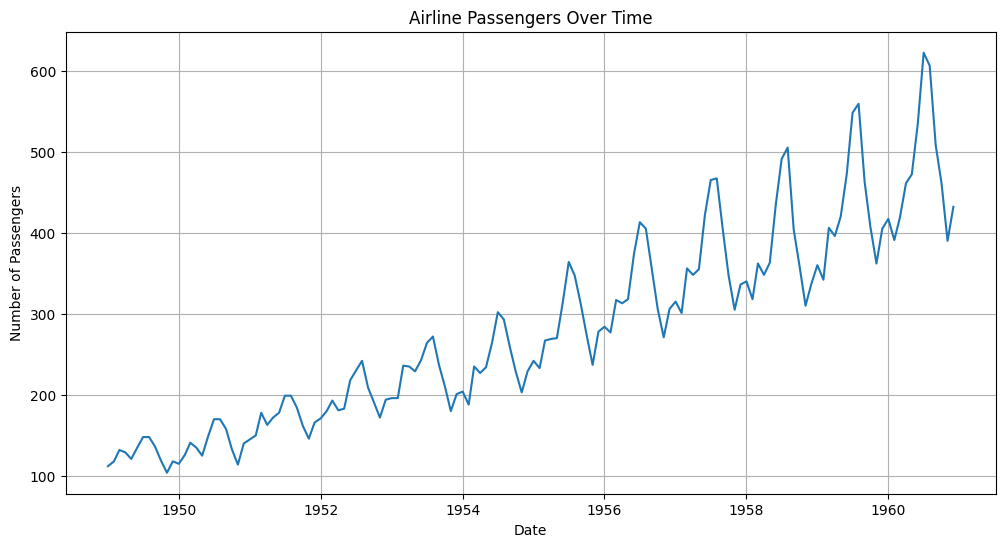

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Passengers'])
plt.title('Airline Passengers Over Time')
plt.xlabel('Date')
plt.ylabel('Number of Passengers')
plt.grid(True)
plt.show()

## Prepare Data for PyTorch LSTM Model

In [ ]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn as nn

# Extract the 'Passengers' column as a NumPy array
data = df['Passengers'].values.astype(float)

# Normalize the data
scaler = MinMaxScaler(feature_range=(-1, 1))
data_normalized = scaler.fit_transform(data.reshape(-1, 1))

# Split data into training and testing sets
train_size = int(len(data_normalized) * 0.75)
test_size = len(data_normalized) - train_size
train_data, test_data = data_normalized[0:train_size,:], data_normalized[train_size:len(data_normalized),:]

print(f"Training data size: {len(train_data)}")
print(f"Testing data size: {len(test_data)}")

# Function to create sequences for LSTM
def create_sequences(data, seq_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length):
        x = data[i:(i + seq_length)]
        y = data[i + seq_length]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

seq_length = 12 # Using 12 months data to predict the next month

X_train, y_train = create_sequences(train_data, seq_length)
X_test, y_test = create_sequences(test_data, seq_length)

# Convert to PyTorch tensors
X_train = torch.from_numpy(X_train).float()
y_train = torch.from_numpy(y_train).float()
X_test = torch.from_numpy(X_test).float()
y_test = torch.from_numpy(y_test).float()

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

Training data size: 108
Testing data size: 36
X_train shape: torch.Size([96, 12, 1])
y_train shape: torch.Size([96, 1])
X_test shape: torch.Size([24, 12, 1])
y_test shape: torch.Size([24, 1])


## Implement the PyTorch LSTM Model

In [ ]:
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_layer_size=100, output_size=1):
        super().__init__()
        self.hidden_layer_size = hidden_layer_size
        self.lstm = nn.LSTM(input_size, hidden_layer_size)
        self.linear = nn.Linear(hidden_layer_size, output_size)
        self.hidden_cell = (torch.zeros(1, 1, self.hidden_layer_size),
                            torch.zeros(1, 1, self.hidden_layer_size))

    def forward(self, input_seq):
        lstm_out, self.hidden_cell = self.lstm(input_seq.view(len(input_seq), 1, -1), self.hidden_cell)
        predictions = self.linear(lstm_out.view(len(input_seq), -1))
        return predictions[-1]

model = LSTMModel()
loss_function = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)

LSTMModel(
  (lstm): LSTM(1, 100)
  (linear): Linear(in_features=100, out_features=1, bias=True)
)


## Train the PyTorch LSTM Model

In [ ]:
epochs = 150

for i in range(epochs):
    for seq, labels in zip(X_train, y_train):
        optimizer.zero_grad()
        model.hidden_cell = (torch.zeros(1, 1, model.hidden_layer_size),
                            torch.zeros(1, 1, model.hidden_layer_size))

        y_pred = model(seq)

        single_loss = loss_function(y_pred, labels)
        single_loss.backward()
        optimizer.step()

    if (i + 1) % 25 == 0:
        print(f'epoch: {i+1:3} loss: {single_loss.item():10.8f}')

print(f'final epoch: {i+1:3} loss: {single_loss.item():10.8f}')

epoch:  25 loss: 0.02308071
epoch:  50 loss: 0.00102192
epoch:  75 loss: 0.00566020
epoch: 100 loss: 0.00004455
epoch: 125 loss: 0.01218816
epoch: 150 loss: 0.00296546
final epoch: 150 loss: 0.00296546


## Evaluate the Model

In [ ]:
model.eval()

# Make predictions on the training data
train_predict = []
with torch.no_grad():
    for seq in X_train:
        model.hidden_cell = (torch.zeros(1, 1, model.hidden_layer_size),
                            torch.zeros(1, 1, model.hidden_layer_size))
        train_predict.append(model(seq).item())

# Make predictions on the test data
test_predict = []
with torch.no_grad():
    for seq in X_test:
        model.hidden_cell = (torch.zeros(1, 1, model.hidden_layer_size),
                            torch.zeros(1, 1, model.hidden_layer_size))
        test_predict.append(model(seq).item())

# Inverse transform the predictions and actual values to original scale
train_predict = scaler.inverse_transform(np.array(train_predict).reshape(-1, 1))
y_train_actual = scaler.inverse_transform(y_train.numpy().reshape(-1, 1))

test_predict = scaler.inverse_transform(np.array(test_predict).reshape(-1, 1))
y_test_actual = scaler.inverse_transform(y_test.numpy().reshape(-1, 1))

# Print the first few inverse-transformed predictions and actuals for verification
print('Train Predictions (first 5):', train_predict[:5].flatten())
print('Train Actual (first 5):', y_train_actual[:5].flatten())
print('Test Predictions (first 5):', test_predict[:5].flatten())
print('Test Actual (first 5):', y_test_actual[:5].flatten())

Train Predictions (first 5): [138.44894934 129.545883   146.99952888 145.98012221 144.54731196]
Train Actual (first 5): [115. 126. 141. 135. 125.]
Test Predictions (first 5): [355.42620198 311.15210021 431.17578936 369.30850121 407.23099419]
Test Actual (first 5): [360. 342. 406. 396. 420.]


## Visualize Results

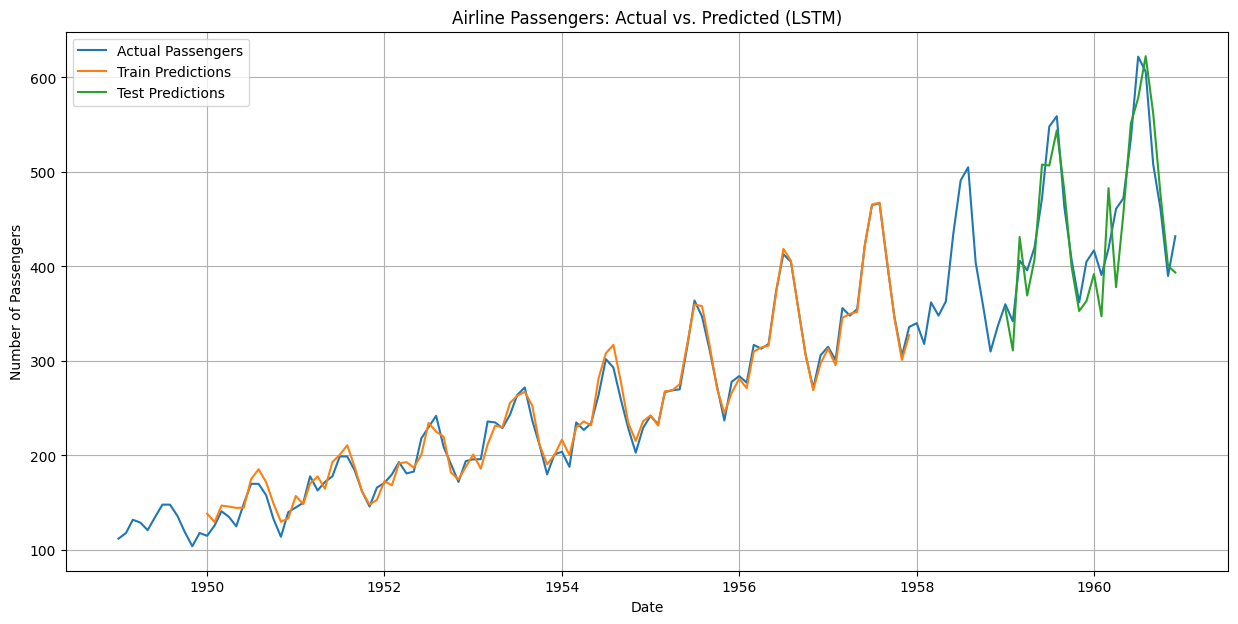

In [ ]:
import matplotlib.pyplot as plt

# Extend predictions to cover the entire original time series length
train_plot_data = np.empty_like(data)
train_plot_data[:] = np.nan
train_plot_data[seq_length:len(train_predict) + seq_length] = train_predict.flatten()

test_plot_data = np.empty_like(data)
test_plot_data[:] = np.nan
test_plot_data[len(train_predict) + (seq_length * 2) : len(data)] = test_predict.flatten()

plt.figure(figsize=(15, 7))
plt.plot(df.index, data, label='Actual Passengers')
plt.plot(df.index, train_plot_data, label='Train Predictions')
plt.plot(df.index, test_plot_data, label='Test Predictions')
plt.title('Airline Passengers: Actual vs. Predicted (LSTM)')
plt.xlabel('Date')
plt.ylabel('Number of Passengers')
plt.legend()
plt.grid(True)
plt.show()

## Calculate Evaluation Metrics

In [ ]:
from sklearn.metrics import mean_squared_error
from math import sqrt

# Calculate RMSE for training data
train_rmse = sqrt(mean_squared_error(y_train_actual, train_predict))
print(f'Train RMSE: {train_rmse:.4f}')

# Calculate RMSE for testing data
test_rmse = sqrt(mean_squared_error(y_test_actual, test_predict))
print(f'Test RMSE: {test_rmse:.4f}')

Train RMSE: 9.3457
Test RMSE: 34.6251


## Summarize Observations and Conclusions

### Observations:
*   **Trend and Seasonality**: The initial visualization clearly showed an upward trend in airline passengers over time, along with strong annual seasonality.
*   **Data Normalization and Sequencing**: The data was successfully normalized using `MinMaxScaler` and transformed into sequences suitable for LSTM input, using the previous 12 months to predict the next.
*   **Model Training**: The LSTM model trained for 150 epochs, and the training loss decreased significantly, indicating that the model learned the underlying patterns in the training data.
*   **Visual Performance**: The plot of actual vs. predicted values shows that the LSTM model was able to capture both the long-term trend and the seasonal fluctuations in the passenger data reasonably well for both training and testing sets.
*   **RMSE Values**: The training RMSE is low (9.3457), suggesting a good fit on the training data. The testing RMSE (34.6251) is higher, which is expected as the model is evaluated on unseen data, but still indicates a reasonable predictive capability for a time series of this nature.

### Conclusions:
*   The PyTorch LSTM model successfully learned the complex patterns (trend and seasonality) present in the Airline Passengers dataset.
*   While the model performed very well on the training data, there is a noticeable increase in error on the test set. This could indicate slight overfitting or simply the inherent difficulty of predicting future values in a dynamic time series.
*   For future improvements, techniques like hyperparameter tuning, using a larger dataset (if available), or exploring more complex LSTM architectures (e.g., stacked LSTMs, bidirectional LSTMs) could further reduce the prediction error.
*   Overall, the implemented LSTM model provides a good baseline for forecasting airline passenger numbers.